# JSON e NumPy

## Quanto affrontato finora

### 1 · Da dove arrivano i valori di un telefono?

In [ ]:
class Phone:                                      # Definisce le caratteristiche comuni ai telefoni.
    def __init__(self, gb, colore):               # Riceve la memoria e il colore scelti da chi crea il telefono.
        self.gb = gb                              # Salva la memoria ricevuta su questo oggetto.
        self.colore = colore                      # Salva il colore ricevuto sullo stesso oggetto.
        self.batteria = 100                       # Ogni telefono comincia con la propria batteria al 100%.

    def telefona(self, num):                      # Riceve il numero da chiamare.
        print("Chiamo", num)                      # Mostra sullo schermo il numero scelto.
        self.batteria -= 1                        # La chiamata consuma un punto di batteria su questo telefono.

    def caratteristiche(self):                    # Restituisce le caratteristiche comuni dei telefoni.
        return f"{self.colore}, {self.gb} GB, batteria {self.batteria}%"  # Restituisce il testo da mostrare.


class Smartphone(Phone):                          # Lo smartphone eredita da Phone anche il metodo telefona.
    def __init__(self, gb, colore, sistema_operativo):  # Qui chi crea lo smartphone sceglie anche il sistema operativo.
        super().__init__(gb, colore)               # Phone imposta memoria, colore e batteria sullo stesso smartphone.
        self.sistema_operativo = sistema_operativo # Smartphone salva il suo attributo aggiuntivo.

    def caratteristiche(self):                    # Ridefinisce il metodo di Phone per includere il sistema operativo.
        return f"{super().caratteristiche()}, {self.sistema_operativo}"  # Riprende il testo di Phone e aggiunge il sistema operativo.


telefono = Phone(4, "bianco")                     # Crea il telefono con 4 GB e batteria a 100.
smart = Smartphone(6, "nero", "Android")          # Crea lo smartphone con 6 GB, Android e batteria a 100.
smart.telefona("123")                             # Chiama dal solo smartphone, che scende a 99.
print(telefono.caratteristiche())                 # Mostra: bianco, 4 GB, batteria 100%
print(smart.caratteristiche())                    # Mostra: nero, 6 GB, batteria 99%, Android

### 2 · Salvare e rileggere le batterie con un CSV

In [ ]:
import csv                                         # Importa gli strumenti per scrivere e leggere il CSV.
from pathlib import Path                           # Importa la classe che rappresenta il percorso del file.

percorso = Path("batterie_ripasso.csv")             # Sceglie il nome del file nella cartella di lavoro.
with percorso.open("w", newline="") as file:        # Apre il CSV in scrittura e lo chiude all’uscita dal blocco.
    scrittore = csv.writer(file)                    # Prepara la scrittura delle righe.
    scrittore.writerow(["colore", "batteria"])       # Scrive i titoli delle due colonne.
    scrittore.writerow([telefono.colore, telefono.batteria])  # Salva il telefono bianco con batteria a 100.
    scrittore.writerow([smart.colore, smart.batteria])        # Salva lo smartphone nero con batteria a 99.

with percorso.open("r", newline="") as file:        # Riapre il CSV in lettura.
    lettore = csv.reader(file)                      # Prepara la lettura dall’inizio del file.
    next(lettore)                                   # Salta la riga dei titoli.
    print(next(lettore))                            # Legge e stampa la riga del telefono bianco.
    print(next(lettore))                            # Legge e stampa la riga dello smartphone nero.

## JSON · Una persona, una lista e un indirizzo

**Gestione File e pathlib Python · slide 16 · Cos'è JSON e come si traduce in Python**

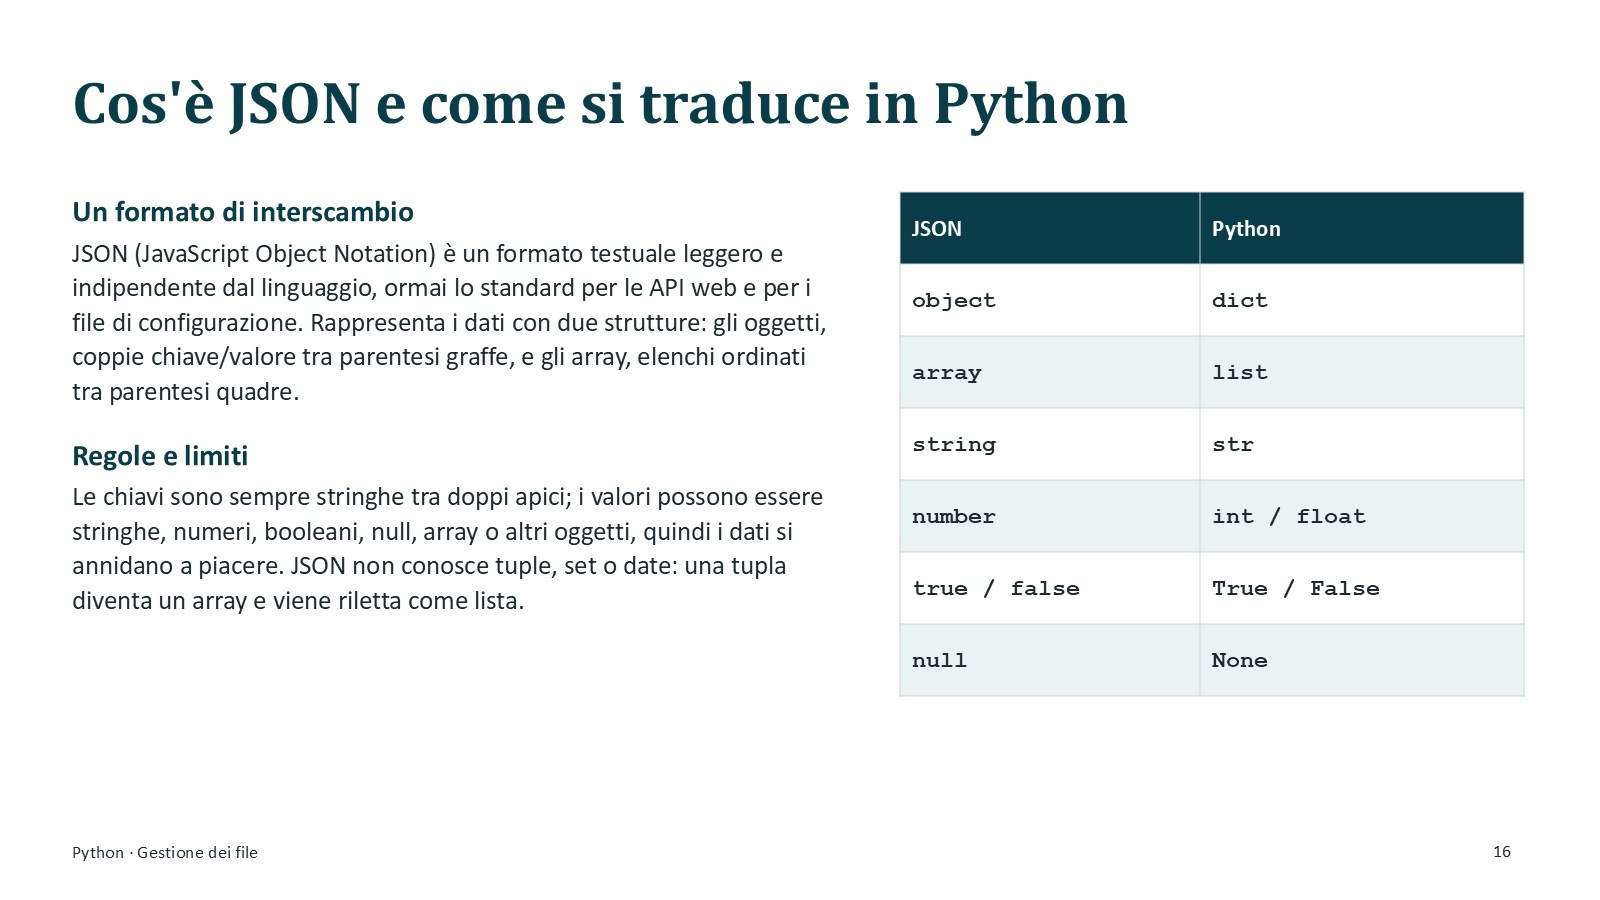


**Gestione File e pathlib Python · slide 17 · Serializzare e deserializzare con il modulo json**

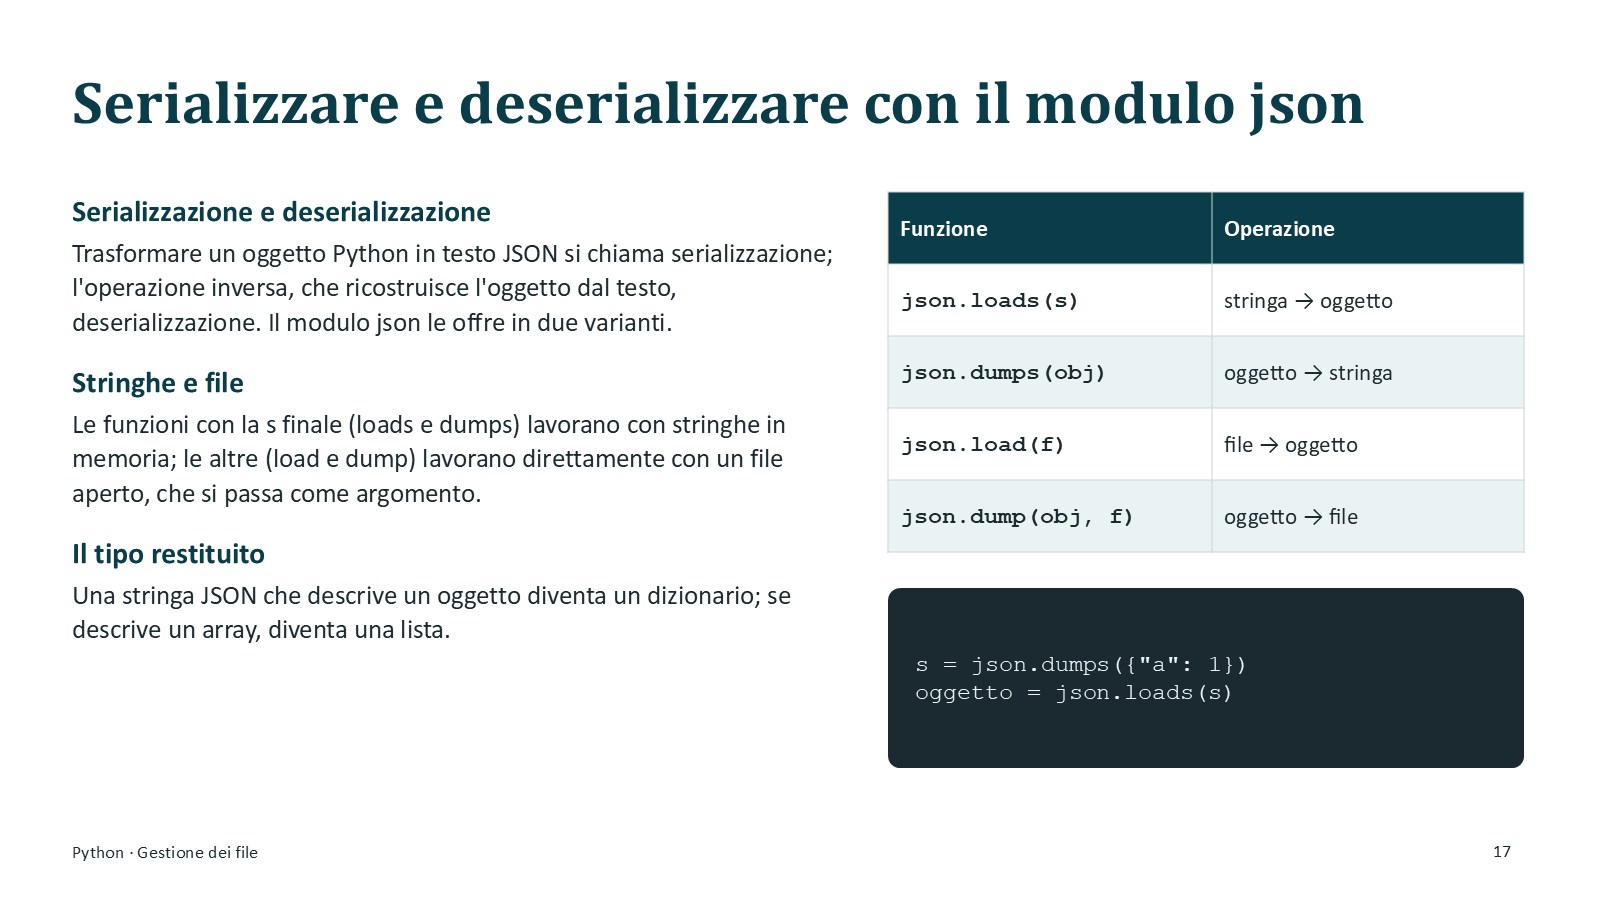


In [ ]:
import json

persona = {
    "nome": "Anna",
    "eta": 30,
    "hobby": ["lettura", "nuoto"],
    "indirizzo": {"citta": "Roma", "cap": "00100"},
}

with open("persona.json", "w") as file:
    json.dump(persona, file)

with open("persona.json", "r") as file:
    persona_letta = json.load(file)

print(persona_letta["nome"])                 # Anna
print(persona_letta["eta"])                  # 30
print(persona_letta["hobby"])                # ['lettura', 'nuoto']
print(persona_letta["hobby"][0])             # lettura
print(persona_letta["indirizzo"]["citta"])   # Roma

**NumPy · slide 2 · Che cos'è NumPy e perché usarlo**

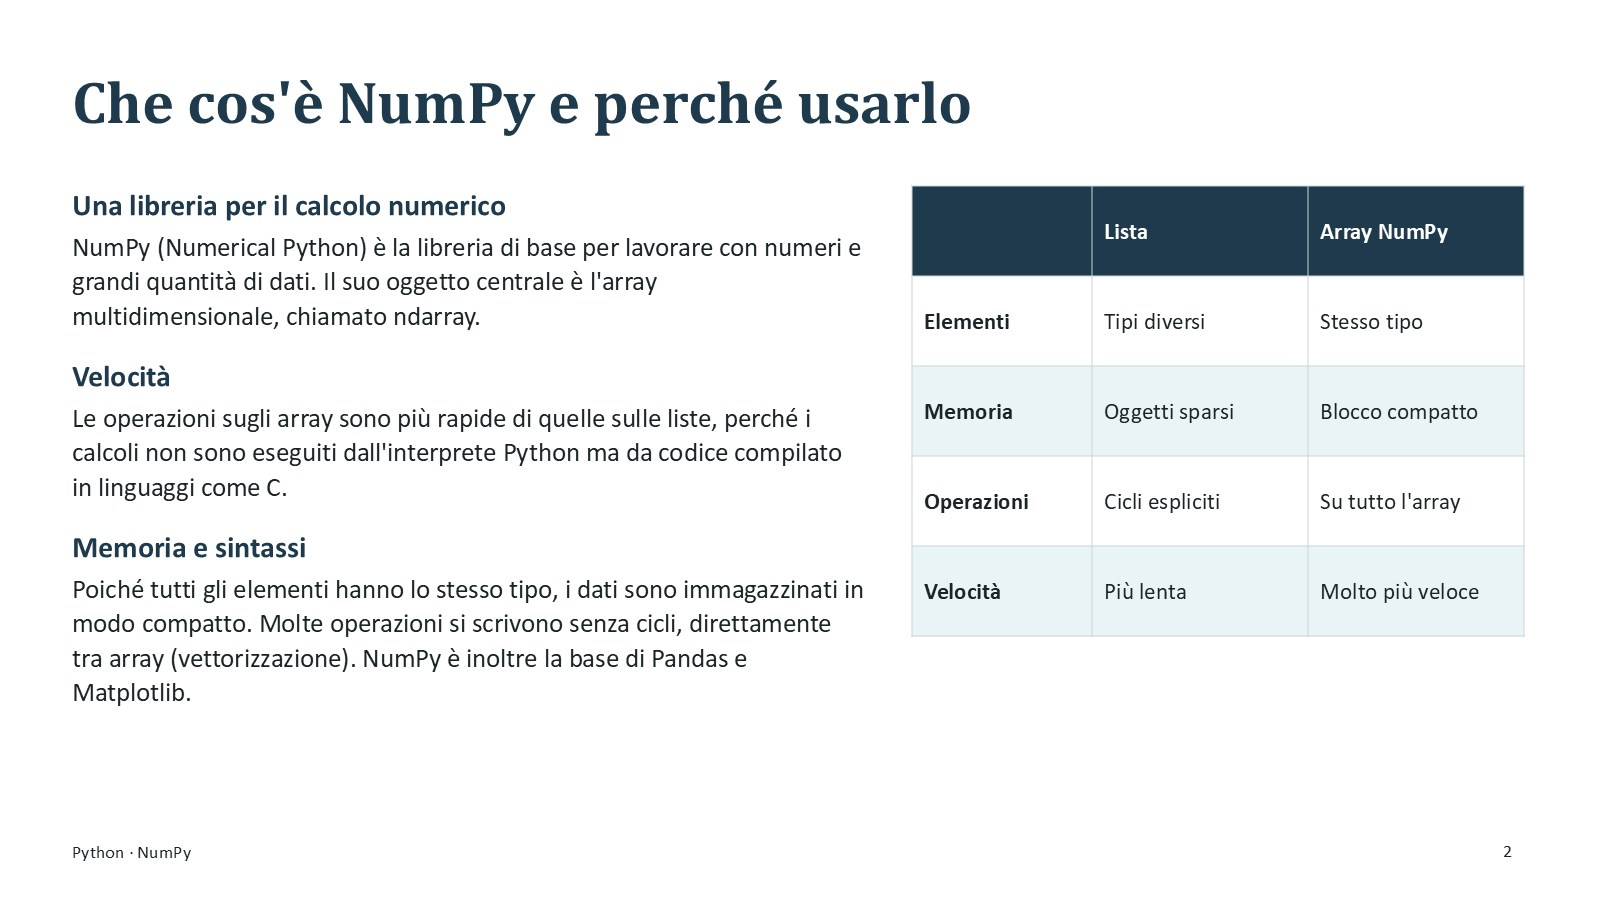


In [ ]:
import numpy as np

lista = [1, 2, 3]
print(lista * 2)           # [1, 2, 3, 1, 2, 3]
print(np.array(lista) * 2) # [2 4 6]

**NumPy · slide 5 · ndarray: array a più dimensioni**

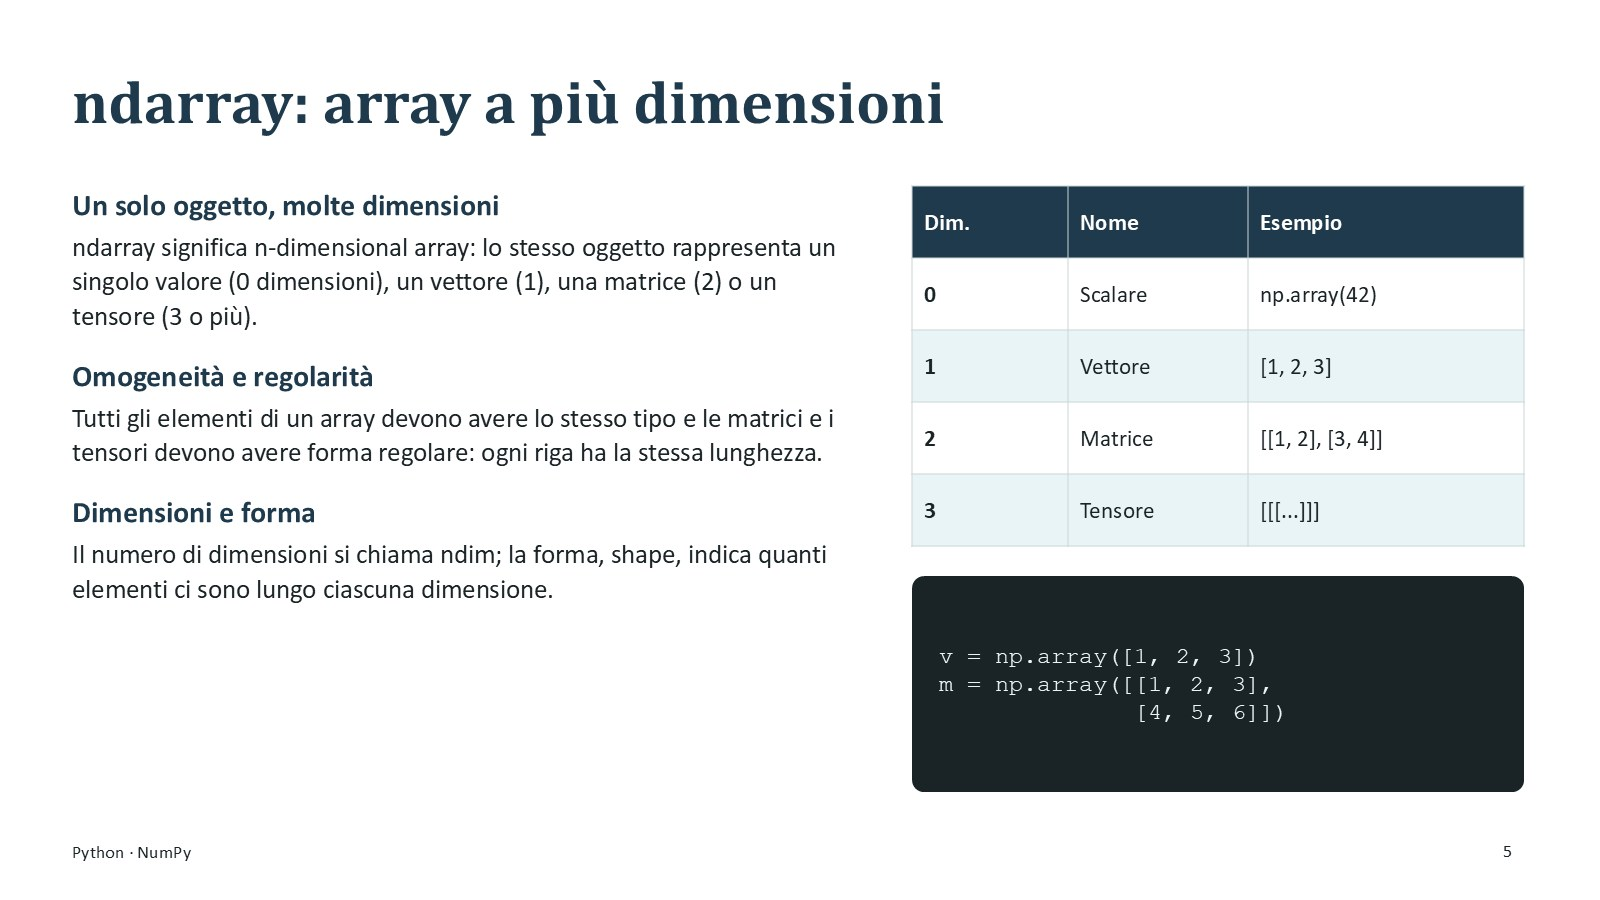


In [ ]:
import numpy as np

v = np.array([1, 2, 3])
m = np.array([[1, 2, 3],
              [4, 5, 6]])
print(v, m)

In [ ]:
import numpy as np

matrice = np.array([[1, 2, 3], [4, 5, 6]])
print(matrice)
print(matrice.shape)  # (2, 3)

**NumPy · slide 7 · Le proprietà di un array**

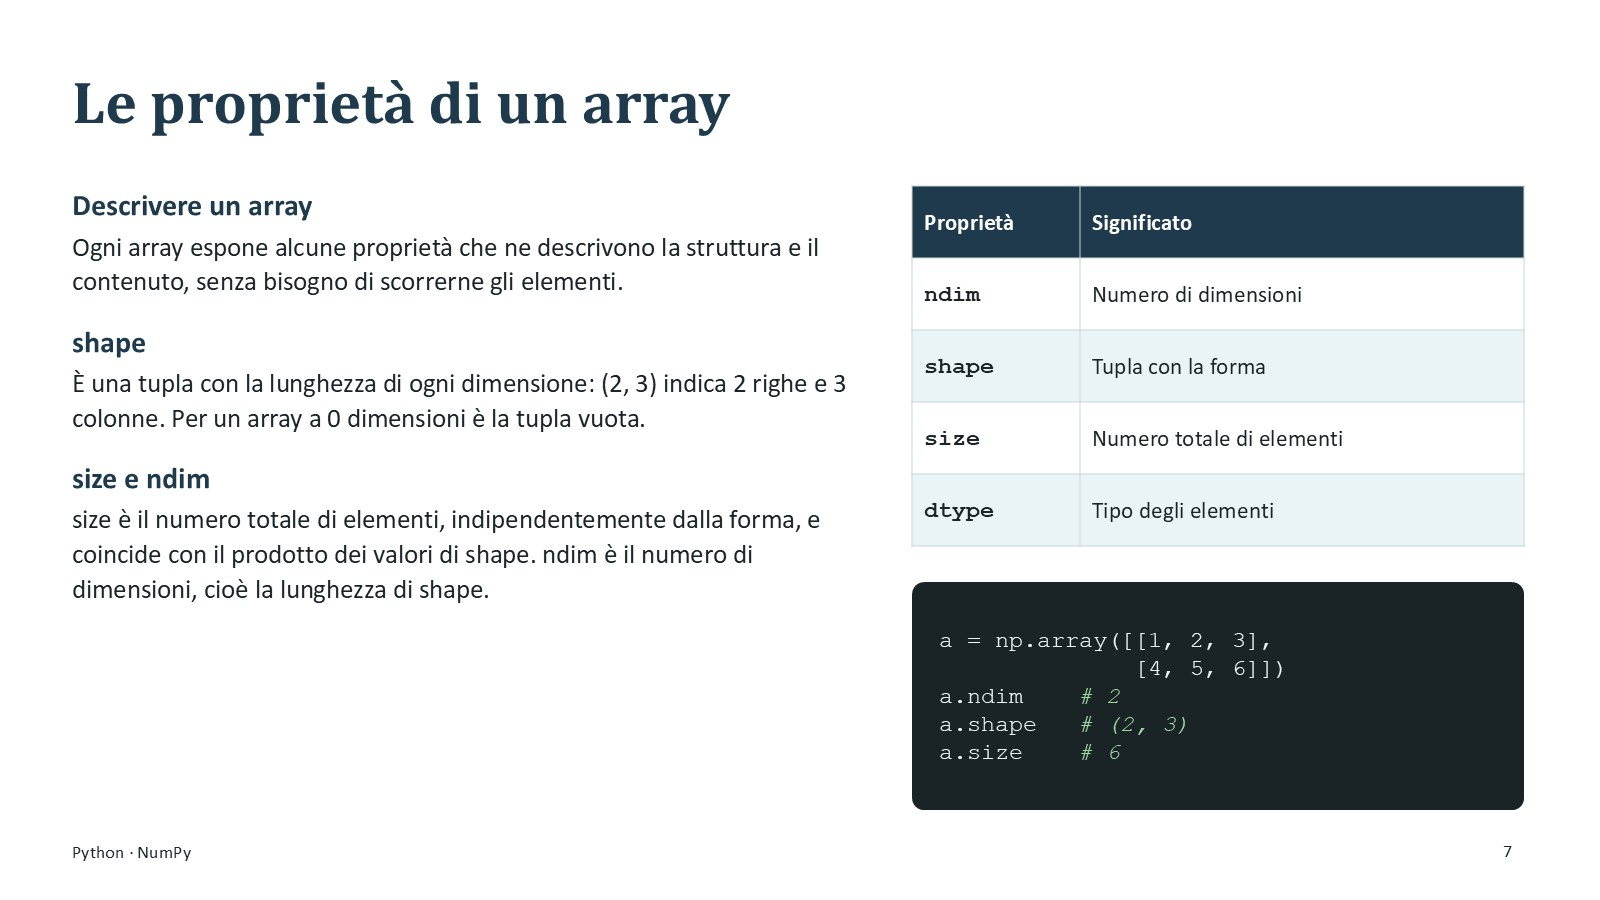


In [ ]:
import numpy as np

a = np.array([[1, 2, 3], [4, 5, 6]])
print(a.ndim, a.shape, a.size)

In [ ]:
matrice = np.array([[1, 2, 3], [4, 5, 6]])
print(matrice.ndim, matrice.shape, matrice.size)
print(matrice.dtype)
testo = np.array(["2", "4"])
print(testo.astype(int) + 1)

**NumPy · slide 8 · Accedere agli elementi**

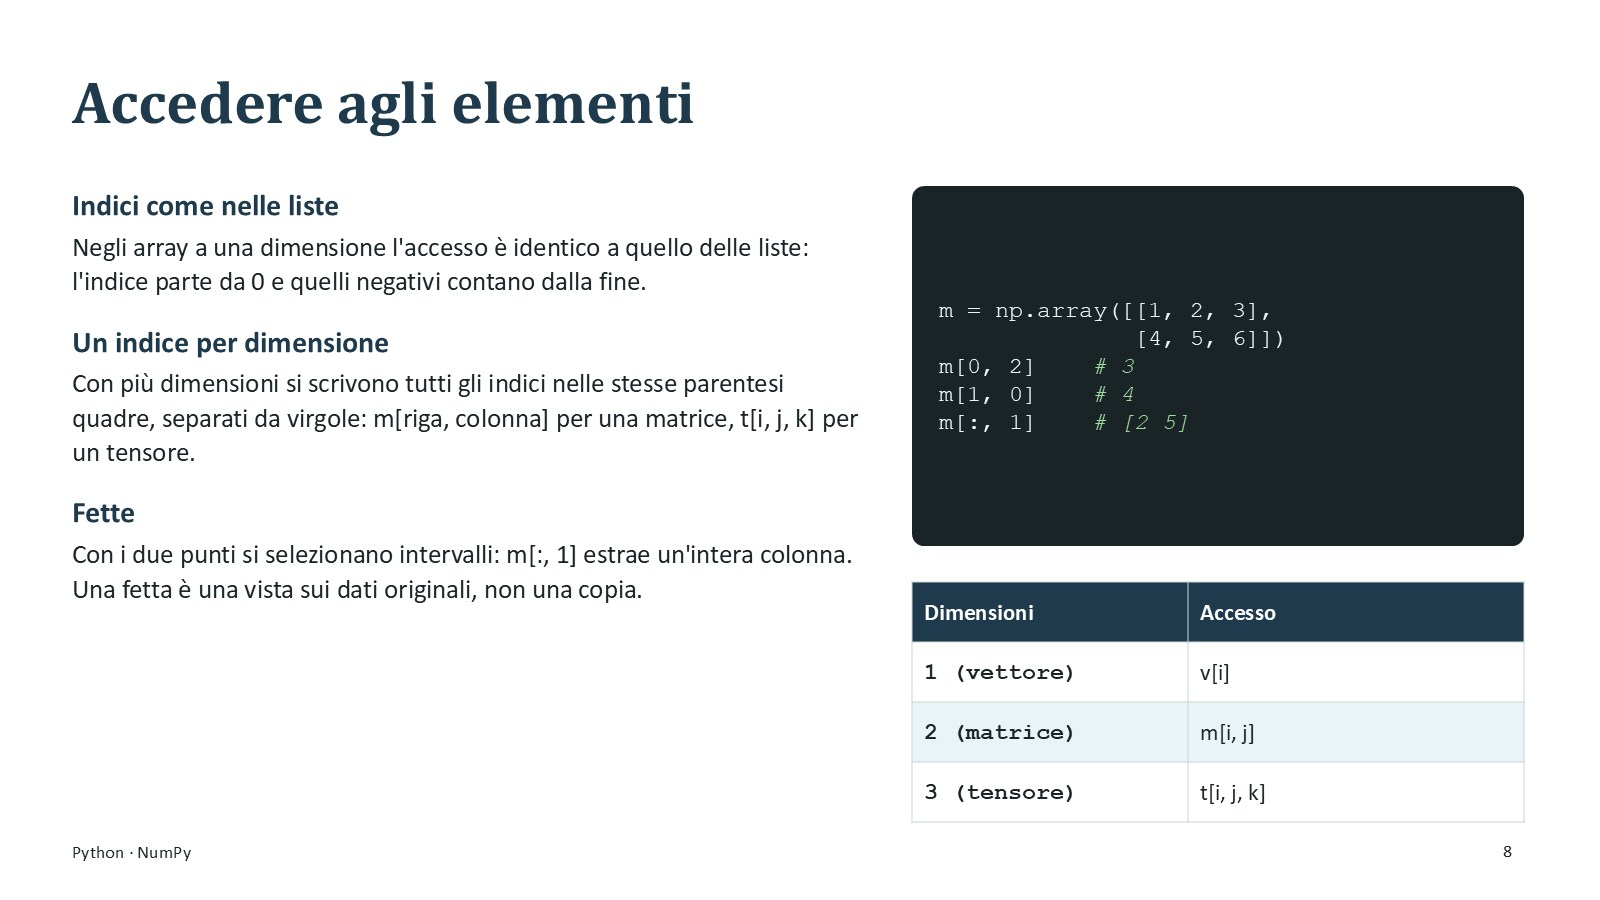


In [ ]:
import numpy as np

m = np.array([[1, 2, 3], [4, 5, 6]])
print(m[0, 2], m[1, 0], m[:, 1])

In [ ]:
matrice = np.array([[1, 2, 3], [4, 5, 6]])
print(matrice[1, 2])
print(matrice[:, 1])
print(matrice[1, :2])
print(matrice[[1, 0], :])

**NumPy · slide 12 · Copy e view**

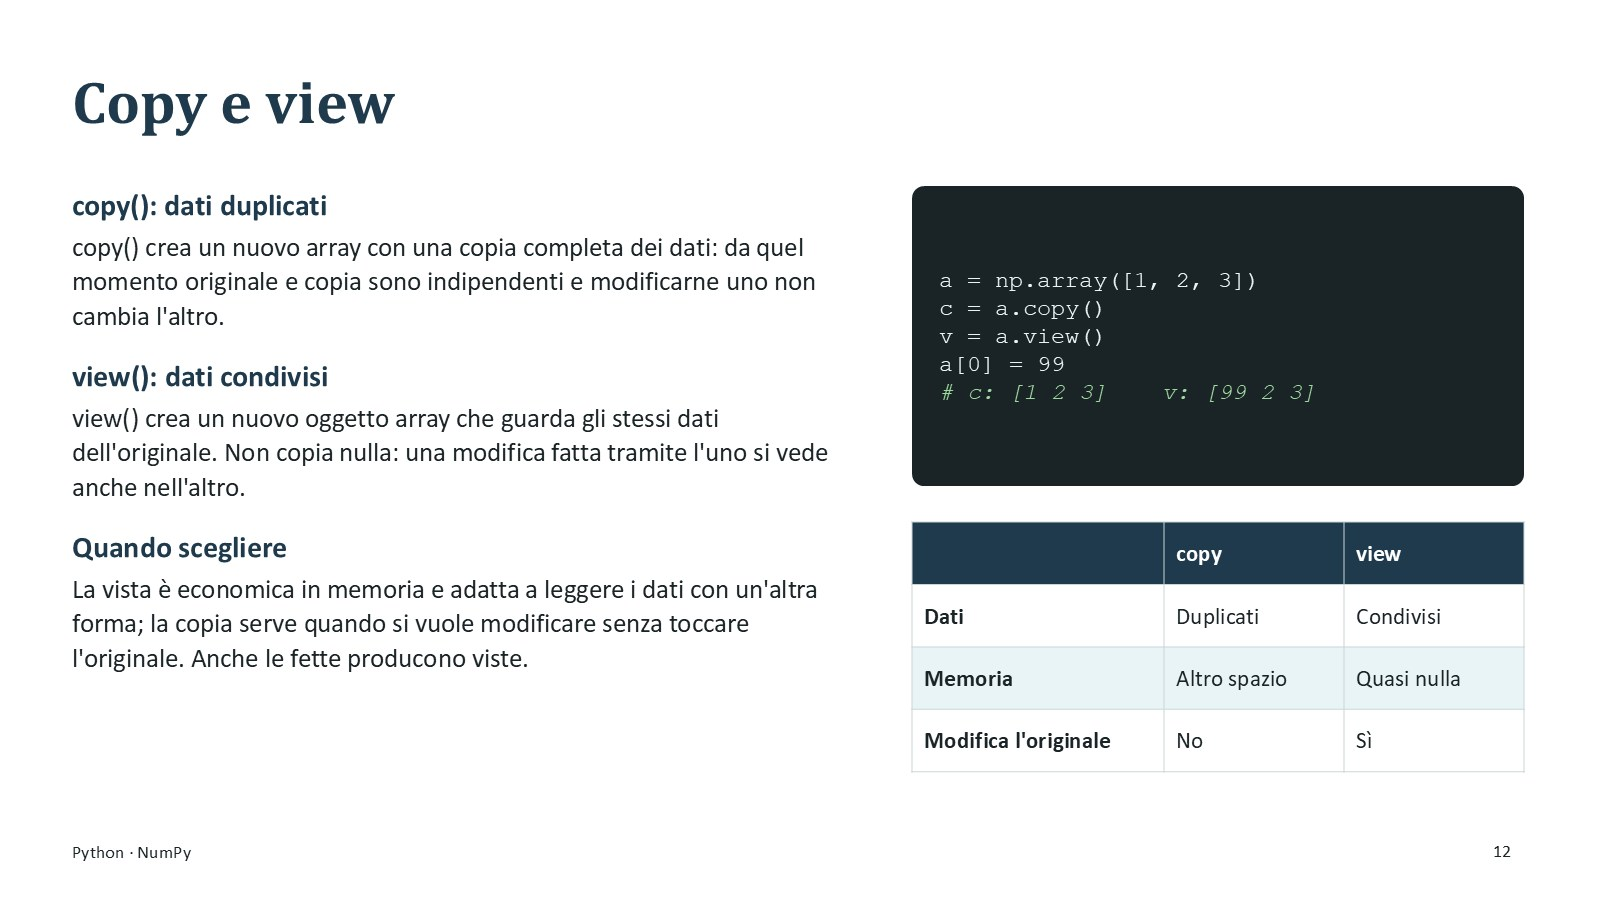


In [ ]:
import numpy as np

a = np.array([1, 2, 3])
c = a.copy()
v = a.view()
a[0] = 99
# c: [1 2 3]    v: [99 2 3]
print(c, v)

In [ ]:
prima = matrice.copy()
colonna = prima[:, 0]
colonna[0] = 9
print(prima[0, 0], matrice[0, 0])

**NumPy · slide 21 · Filtrare con maschere booleane**

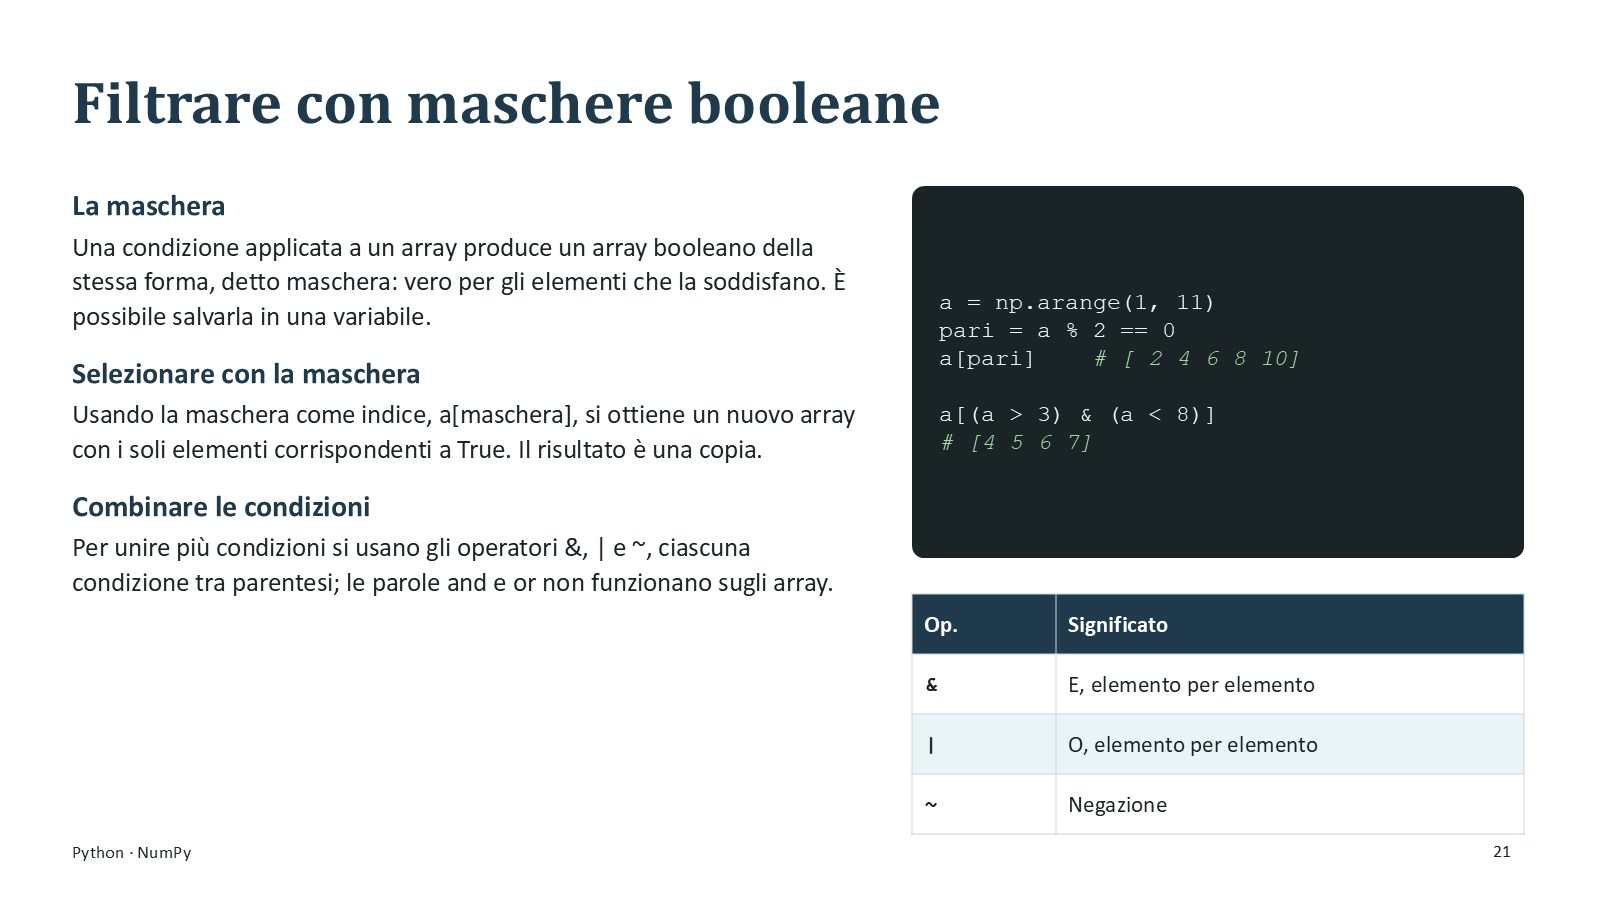


In [17]:
import numpy as np

a = np.arange(1, 11)
pari = a % 2 == 0
print(a[pari])

print(a[(a > 3) & (a < 8)])
# [4 5 6 7]

[ 2  4  6  8 10]
[4 5 6 7]


In [ ]:
print(matrice >= 4)
print(matrice[matrice >= 4])

**NumPy · slide 23 · Che cosa sono le ufunc**

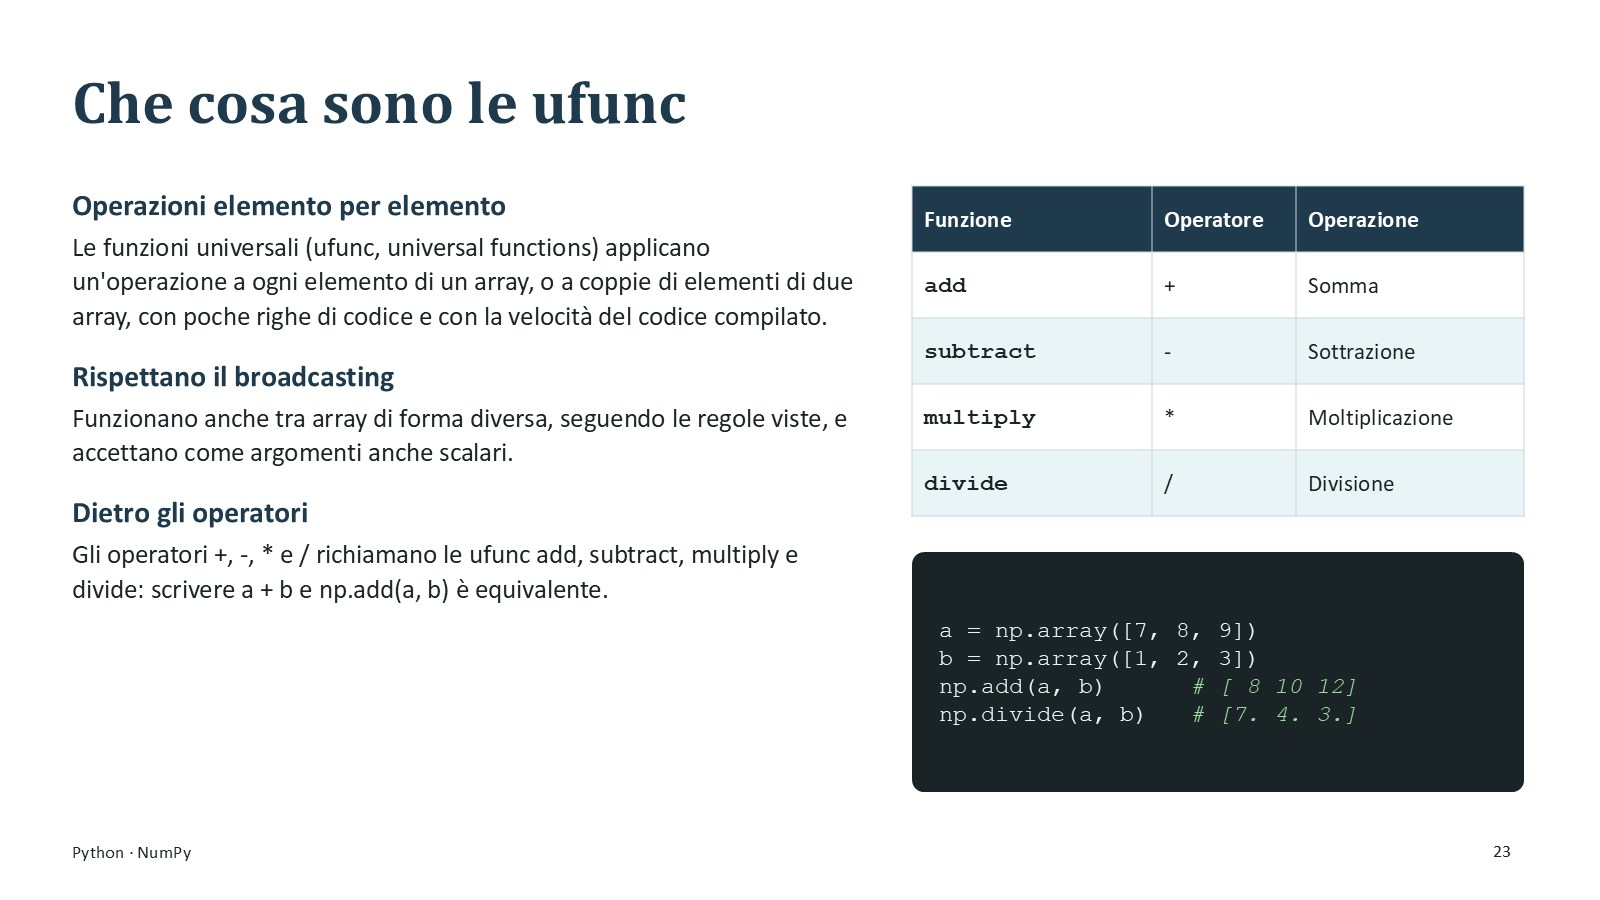


In [ ]:
import numpy as np

a = np.array([7, 8, 9])
b = np.array([1, 2, 3])
print(np.add(a, b))
print(np.divide(a, b))

In [ ]:
doppio = matrice * 2
print(doppio)
print(np.add(matrice, 1))
print(np.sqrt(np.array([4, 9, 16])))

**NumPy · slide 16 · Broadcasting: un esempio passo per passo**

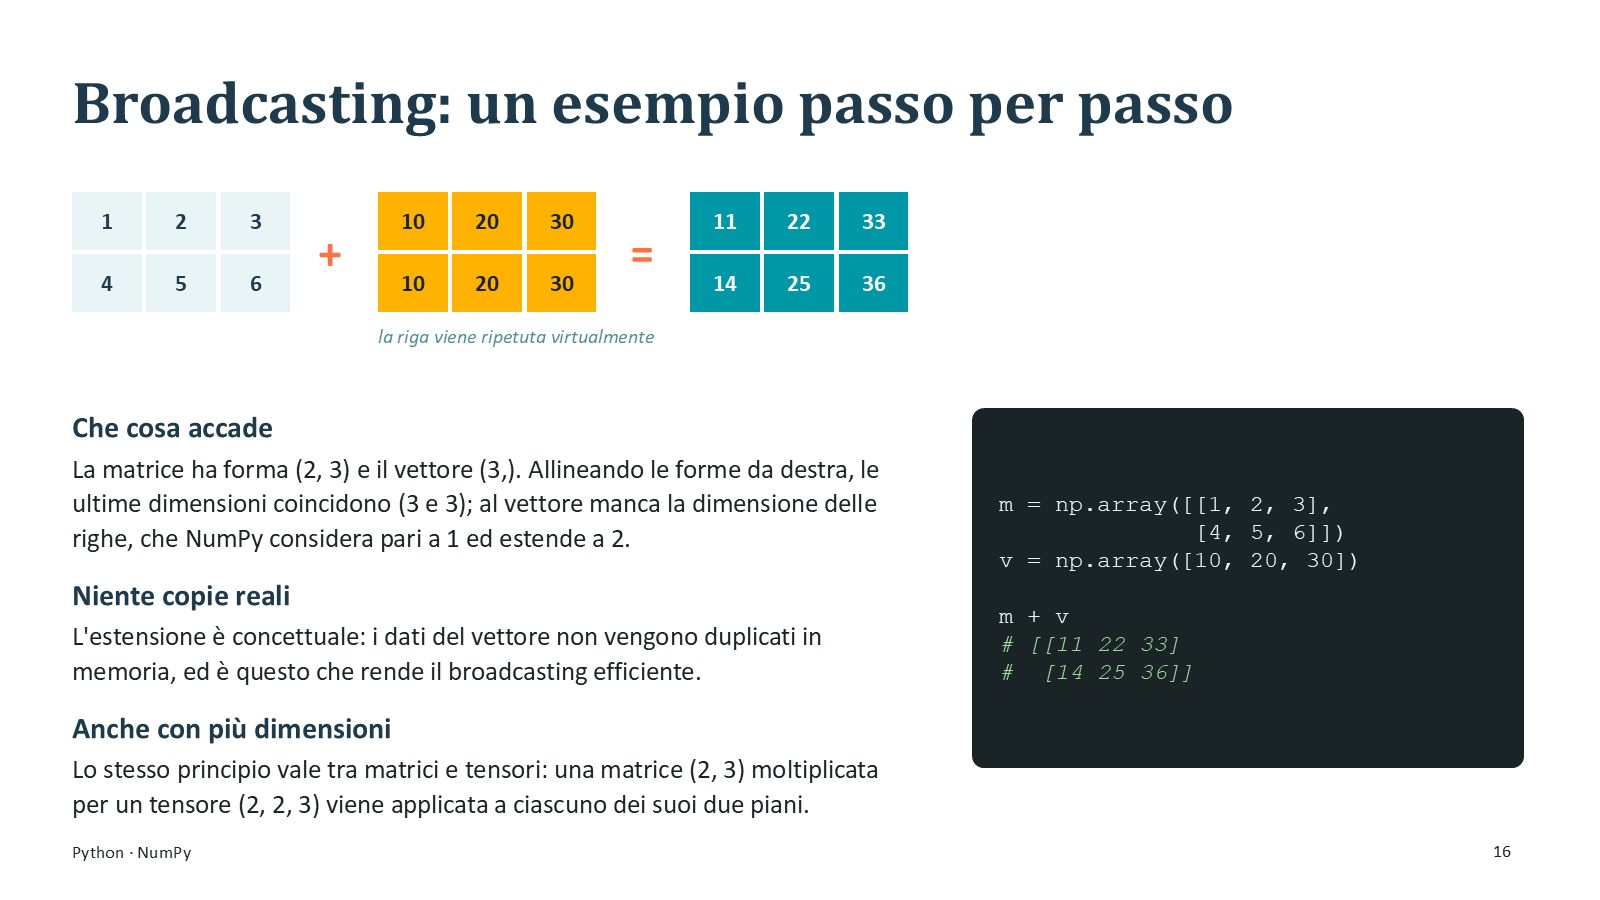


In [ ]:
import numpy as np

m = np.array([[1, 2, 3],
              [4, 5, 6]])
v = np.array([10, 20, 30])

print(m + v)
# [[11 22 33]
#  [14 25 36]]

In [ ]:
per_colonna = np.array([10, 20, 30])
print(matrice + per_colonna)

per_riga = np.array([[10], [20]])
print(matrice + per_riga)

**NumPy · slide 25 · Funzioni statistiche**

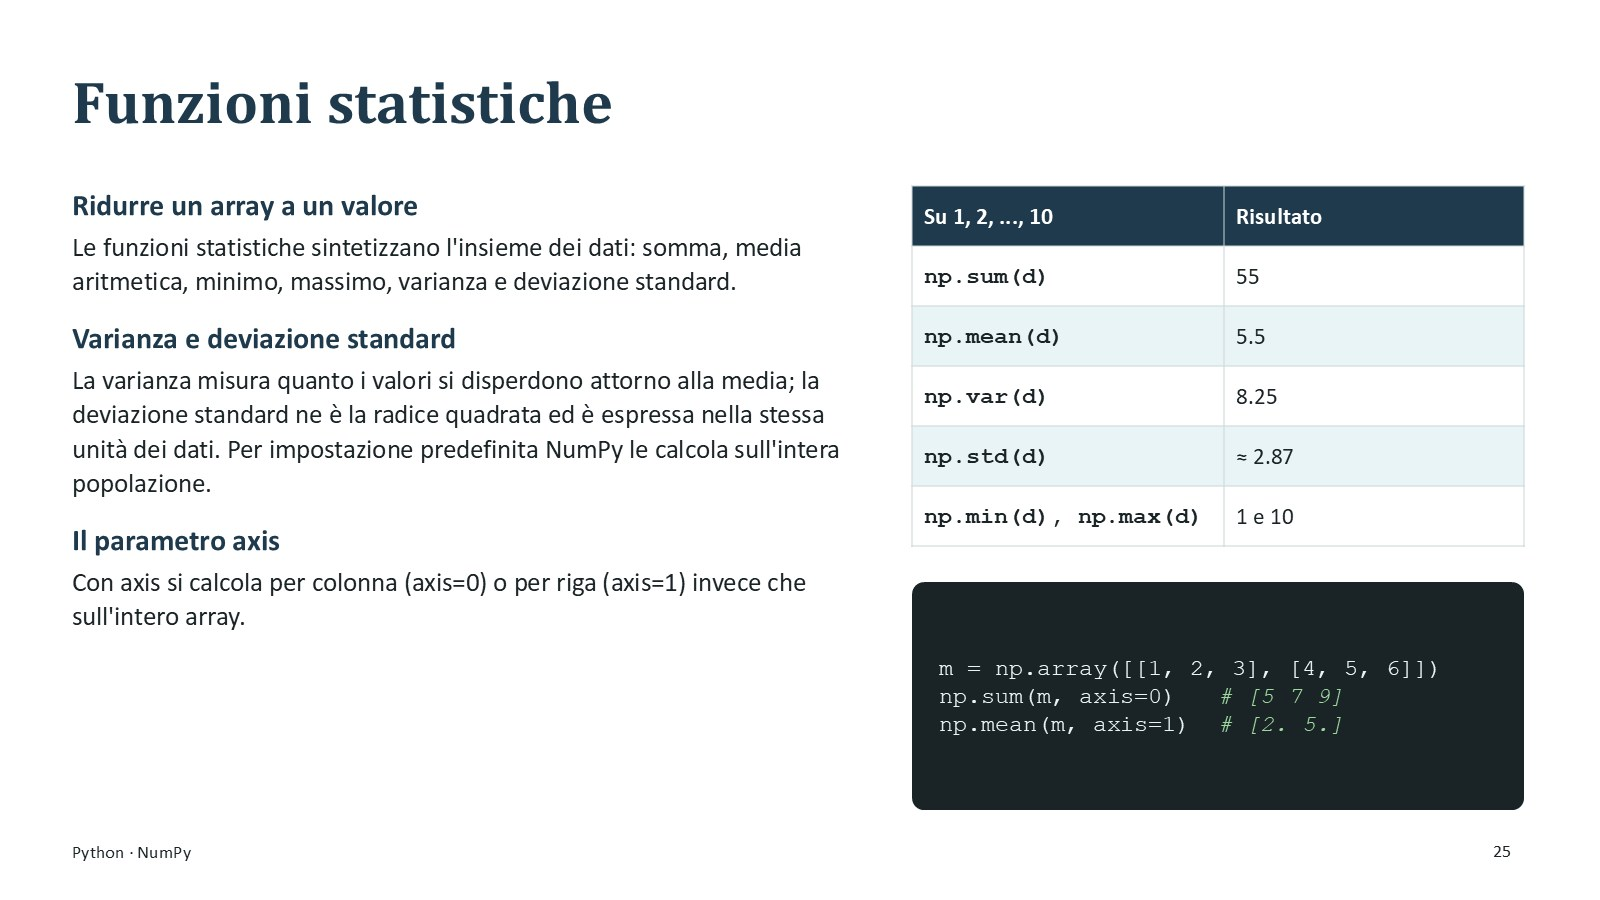


In [ ]:
import numpy as np

m = np.array([[1, 2, 3], [4, 5, 6]])
print(np.sum(m, axis=0))
print(np.mean(m, axis=1))

In [ ]:
print(matrice.sum())
print(matrice.sum(axis=0))
print(matrice.sum(axis=1))
print(matrice.mean(axis=1))
print(matrice.min(), matrice.max(), np.median(matrice))

Apri il notebook separato **[Lezione 4 · E01 · Ripasso](ripasso_python/Lezione%204%20-%20E01%20-%20Ripasso.ipynb)** per le domande e la rubrica telefonica.